# Disease Prediction (Breast Cancer)
Goal: Predict whether a tumor is Malignant or Benign using ML.

## Step 1: Import Libraries

In [9]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, roc_curve,
                             confusion_matrix, classification_report)

## Step 2: Load Dataset
Breast Cancer Wisconsin dataset (569 patients, 30 features), loaded from scikit-learn.

In [10]:
data = load_breast_cancer()
df = pd.DataFrame(data.data, columns=data.feature_names)
df["target"] = data.target

print(df.shape)                      # (569, 31)
print(df["target"].value_counts())   # દરેક વર્ગની સંખ્યા
print("ખૂટતી કિંમતો:", df.isnull().sum().sum())
df.head()

(569, 31)
target
1    357
0    212
Name: count, dtype: int64
ખૂટતી કિંમતો: 0


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


## Step 3: Train-Test Split
80% data for training, 20% for testing.

In [11]:
X = df.drop("target", axis=1)
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(X_train.shape, X_test.shape)

(455, 30) (114, 30)


## Step 4: Feature Scaling
Used StandardScaler so all features are on the same scale.

In [12]:
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

## Step 5: Model Training and Comparison
Trained Logistic Regression, SVM and Random Forest. Compared using Accuracy, Precision, Recall, F1 and ROC-AUC.

In [13]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "SVM": SVC(probability=True, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
}

results, probs = [], {}
for name, model in models.items():
    model.fit(X_train_s, y_train)
    pred = model.predict(X_test_s)
    prob = model.predict_proba(X_test_s)[:, 1]
    probs[name] = prob
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, prob),
    })

results_df = pd.DataFrame(results).round(4)
results_df

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.9825,0.9861,0.9861,0.9861,0.9954
1,SVM,0.9825,0.9861,0.9861,0.9861,0.9950
2,Random Forest,0.9561,0.9589,0.9722,0.9655,0.9932


## Step 6-7: ROC Curve and Confusion Matrix

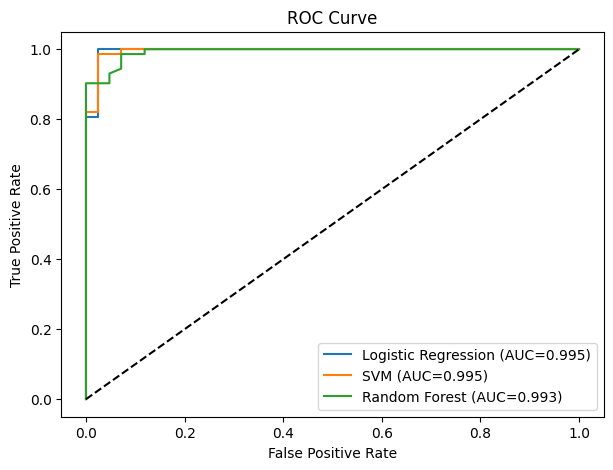

In [14]:
plt.figure(figsize=(7, 5))
for name, prob in probs.items():
    fpr, tpr, _ = roc_curve(y_test, prob)
    plt.plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, prob):.3f})")
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

## Step 8: Feature Importance

Best model: Logistic Regression


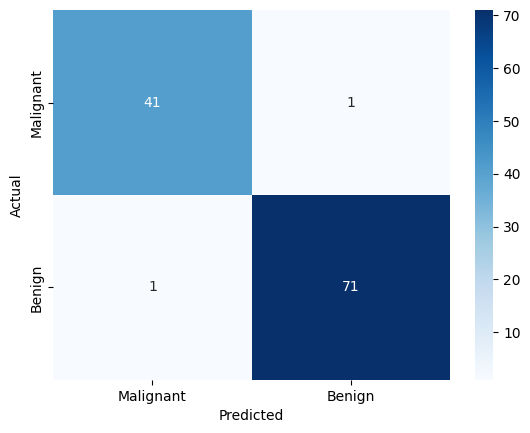

              precision    recall  f1-score   support

   Malignant       0.98      0.98      0.98        42
      Benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



In [15]:
best = results_df.sort_values("ROC-AUC", ascending=False).iloc[0]["Model"]
print("Best model:", best)

best_pred = models[best].predict(X_test_s)
sns.heatmap(confusion_matrix(y_test, best_pred), annot=True, fmt="d", cmap="Blues",
            xticklabels=["Malignant", "Benign"], yticklabels=["Malignant", "Benign"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

print(classification_report(y_test, best_pred, target_names=["Malignant", "Benign"]))

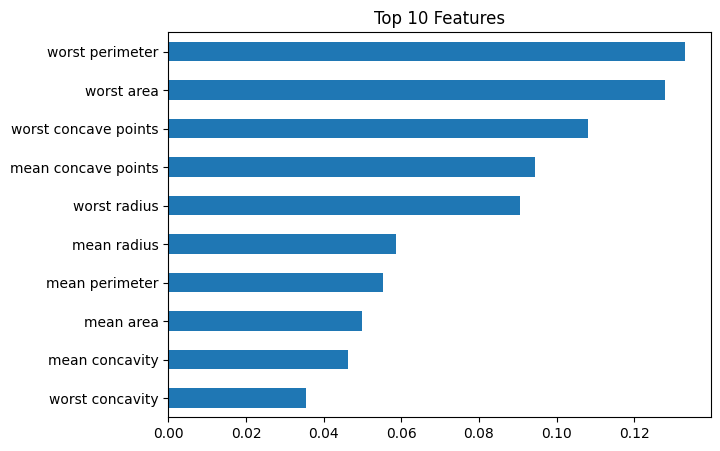

In [16]:
imp = pd.Series(models["Random Forest"].feature_importances_, index=X.columns)
imp.sort_values().tail(10).plot(kind="barh", figsize=(7, 5), title="Top 10 Features")
plt.show()

## Conclusion

- Three models were compared: Logistic Regression, SVM and Random Forest.
- **Best model: Logistic Regression** with Accuracy 98.25%, Precision 98.61%,
  Recall 98.61%, F1-Score 98.61% and ROC-AUC 0.9954.
- SVM performed almost the same (Accuracy 98.25%, ROC-AUC 0.9950).
- Random Forest scored slightly lower (Accuracy 95.61%, ROC-AUC 0.9932), but had
  the highest Recall (97.22%).
- Simple linear models worked best because the features are well separated
  after scaling and the dataset is small and clean.
- High Recall is important in medical problems, because missing a real case
  is more costly than a false alarm.